# Recognising Tom and Jerry in Cartoon Frames with Transfer Learning

## Introduction

*Tom and Jerry* is a classic cartoon about a grey-blue cat, Tom, who is always chasing a small brown mouse, Jerry. In this notebook we build a model that looks at a single frame from the cartoon and decides which characters are in it. Each frame belongs to one of **four classes**:

- `tom`: only Tom is in the frame
- `jerry`: only Jerry is in the frame
- `both`: Tom and Jerry are both in the frame
- `neither`: neither character is in the frame (empty scenes, or other characters such as Spike the bulldog)

This is harder than it sounds. Jerry is often tiny or only partly visible, frames taken from moving video can be blurred, and the backgrounds are full of the same browns and greys as the characters. Rules such as "look for a grey cat shape" are very hard to write as code.

Instead, we use a **deep neural network** that learns which visual features matter from thousands of labelled frames. Training such a network from scratch would need far more data and computing time, so we use **transfer learning**: we start from ResNet-34, a network that already learned general visual features (edges, textures, shapes) from the ImageNet dataset, and adapt it to our four classes. ImageNet contains photographs, not cartoons, so this is also a test of how well transfer learning carries over to a very different style of image.

The notebook is organised as follows:

1. **Data**: download the frames and create the labels.
2. **Exploratory data analysis**: look at example frames and count the images in each class.
3. **Modeling**: fine-tune ResNet-34 and measure its error rate on frames it did not train on.
4. **Model assessment**: find which classes are confused and which frames the model gets most wrong.
5. **Deployment**: use the model on a frame from the dataset and on a picture of Jerry from outside the dataset.
6. **Conclusion**: summarise the results and limitations.

## Data source

The data are frames taken from the *Tom and Jerry* cartoon show, published on Kaggle by user balabaskar as the **Tom and Jerry Image Classification** dataset:

- Dataset page: https://www.kaggle.com/datasets/balabaskar/tom-and-jerry-image-classification

The dataset contains 5,478 labelled frames (JPEG images, mostly in widescreen format), stored in four folders: `tom`, `jerry`, `tom_jerry_1` (both characters) and `tom_jerry_0` (neither character). We download it with the `kagglehub` library, which needs no Kaggle account for public datasets.

The images are frames from a copyrighted cartoon, so we use them for learning and research only. See the Kaggle page for the dataset's terms of use.

The extra test picture at the end of the notebook is the image of Jerry used on Jerry Mouse's English Wikipedia page: https://en.wikipedia.org/wiki/Jerry_Mouse

## Set up

### Hardware

Training a neural network is much faster on a GPU. In Google Colab, click **Runtime → Change runtime type** and set **Hardware accelerator** to **T4 GPU**. The results reported below were produced in Colab with **Runtime → Run all**.

### Libraries

We import the `fastai` vision library, which provides the tools for loading images and training the network, and `fastcore`, the set of helper utilities that `fastai` is built on. We also import `kagglehub` to download the data, `pandas` to count images, `requests` to download a picture from the web, and `matplotlib` and `seaborn` to plot predictions.

In [ ]:
from fastai.vision.all import *
from fastcore.all import *
import kagglehub
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

The imports produce no output, which means all the libraries are installed. All of them come preinstalled in Google Colab.

### Make the results reproducible

Splitting the data and training the network both involve randomness, so each run would give slightly different numbers. Setting a random seed makes every run produce the same split and (as far as the GPU allows) the same trained model, so the figures and numbers discussed below can be reproduced.

In [ ]:
set_seed(42, reproducible=True)

This cell has no output. From here on, the random choices made by Python, NumPy and PyTorch follow the same sequence on every run.

# Data processing and exploratory data analysis

## Load the data

Download the dataset from Kaggle and get the path to the folder where it is stored. `kagglehub` returns the path as text, so we turn it into a `Path` object, which lets us build file paths with the `/` operator.

In [ ]:
dataset_path = Path(kagglehub.dataset_download("balabaskar/tom-and-jerry-image-classification"))
print("Path to dataset files:", dataset_path)

Using Colab cache for faster access to the 'tom-and-jerry-image-classification' dataset.
Path to dataset files: /kaggle/input/tom-and-jerry-image-classification


The output shows that the dataset was found (Colab keeps a cached copy of popular Kaggle datasets, so the download is fast) and is stored under `/kaggle/input/tom-and-jerry-image-classification`. On another machine the path will be different, but the rest of the notebook does not depend on it.

### Find the images

The images sit in the four class folders a few levels down inside the download. Rather than typing the exact path, we search for the folder that contains the `tom` folder and call it `image_folder`. We then list every image file inside it.

In [ ]:
image_folder = [folder.parent for folder in dataset_path.rglob('tom') if folder.is_dir()][0]
print("Image folder:", image_folder)

file_names = get_image_files(image_folder)
f'We have {len(file_names)} images'

Image folder: /kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry


'We have 5478 images'

The class folders are inside `tom_and_jerry/tom_and_jerry`, and together they hold 5,478 images. This is enough data to fine-tune a pretrained network, but far too little to train a large network from scratch.

### Look at an example image

Open one image and display it as a thumbnail 192 pixels wide. Change the index in `file_names[65]` to look at a different image.

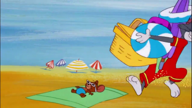

In [ ]:
example_image = PILImage.create(file_names[65])
example_image.to_thumb(192)

Image number 65 is a wide beach scene with striped umbrellas. A character carrying a picnic basket walks in from the right edge with only part of the body visible, and a small figure lies on a green towel in the foreground. The frame is much wider than it is tall (192 × 108 pixels as a thumbnail), and the character fills only a small part of it, which is typical of the dataset and shows why the task is hard.

## Data processing

### Process the image labels

Unlike many image datasets, the label is not in the file name. File names are just frame numbers, such as `frame1234.jpg`. Instead, the label is the **name of the folder** each image is stored in. We examine the first five file paths.

In [ ]:
file_names[:5]

[Path('/kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry/tom_jerry_1/frame2268.jpg'), Path('/kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry/tom_jerry_1/frame2274.jpg'), Path('/kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry/tom_jerry_1/frame4213.jpg'), Path('/kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry/tom_jerry_1/frame3782.jpg'), Path('/kaggle/input/tom-and-jerry-image-classification/tom_and_jerry/tom_and_jerry/tom_jerry_1/frame4327.jpg')]

The first five files all come from the `tom_jerry_1` folder and are named only by frame number (`frame2268.jpg`, `frame2274.jpg`, …), confirming that the label must come from the folder. Each image is stored in one of four folders:

| Folder | Meaning | Label we will use |
|---|---|---|
| `tom` | only Tom is in the frame | `tom` |
| `jerry` | only Jerry is in the frame | `jerry` |
| `tom_jerry_1` | Tom **and** Jerry are both in the frame | `both` |
| `tom_jerry_0` | neither character is in the frame | `neither` |

We define a function that labels each image according to its folder. The folder names `tom_jerry_0` and `tom_jerry_1` are not very readable, so we translate them into `neither` and `both`.

In [ ]:
folder_to_label = {"tom":         "tom",
                   "jerry":       "jerry",
                   "tom_jerry_1": "both",
                   "tom_jerry_0": "neither"}

def label_function(file_name):
    return folder_to_label[file_name.parent.name]

Defining the dictionary and the function produces no output. For example, `label_function` returns `"both"` for the five files listed above, because they are all in the `tom_jerry_1` folder.

### Process the images

First create a `DataBlock`, a recipe that tells `fastai` how to build the training data. Its arguments say:

- `blocks`: the inputs are images and the outputs are categories (a classification task).
- `get_items`: how to find the data, here by listing all image files.
- `get_y`: how to get the label for each image, using our labelling function.
- `splitter`: how to divide the data. By default `RandomSplitter` keeps a random 20% of the images aside as a **validation set**, which the model never trains on and which we use to measure its accuracy. We use `seed=1` so the split is the same every time.
- `item_tfms`: a transformation applied to each image. The pretrained network expects inputs of a fixed size, so every image is resized to 224 × 224 pixels.

In [ ]:
data_block = DataBlock(blocks    = (ImageBlock, CategoryBlock),
                       get_items = get_image_files,
                       get_y     = label_function,
                       splitter  = RandomSplitter(seed=1),
                       item_tfms = Resize(224))

This cell has no output: the `DataBlock` only describes the steps; no images are loaded yet.

### Load the data

Now we apply the recipe to the image folder. This creates `dls`, a `DataLoaders` object that serves the images to the model in small batches, with separate loaders for the training and validation sets.

In [ ]:
dls = data_block.dataloaders(image_folder)

This cell has no visible output. With a 20% validation split, the 5,478 images are divided into 4,383 training images and 1,095 validation images.

## Exploratory data analysis

### Example frames

The `show_batch()` method shows nine frames from the training set together with their labels, so we can check that the labels make sense and see how varied the frames are.

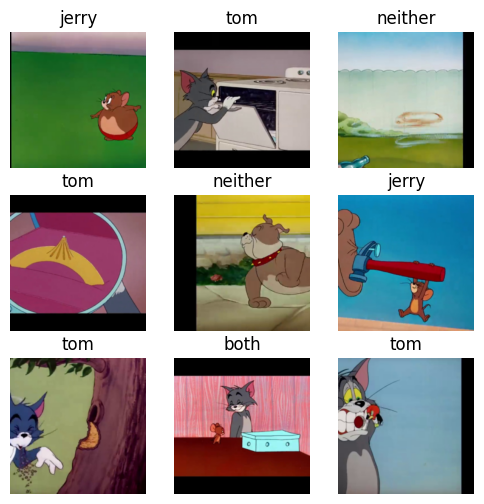

In [ ]:
dls.show_batch(figsize=(6, 6))

The batch contains four `tom` frames, two `jerry` frames, two `neither` frames and one `both` frame, and the labels match what is visible. Several features of the data stand out:

- **Size and position.** Jerry is often tiny: in one `jerry` frame he is a small figure next to a large hand holding a hammer, and in the `both` frame he is a small brown shape at Tom's feet.
- **Partial views.** One `tom` frame shows only a large yellow object under a magnifying glass, with Tom barely visible, so the model must sometimes recognise a character from a small part.
- **Other characters.** One `neither` frame shows Spike the bulldog, so `neither` does not mean an empty scene; it means no Tom and no Jerry.
- **Shape and borders.** The frames were widescreen, so after resizing to a square many have black bars at the top, bottom or side.
- **Colour.** Tom is grey-blue and Jerry is brown, but the backgrounds contain the same colours, so a simple colour rule would not work.

Rules like "find the grey cat shape" or "find the brown mouse ears" are hard to write down as code. This is the reason to use a neural network that learns useful features from the images by itself.

### Class balance

Count the number of images in each class.

In [ ]:
class_counts = pd.Series([label_function(file_name) for file_name in file_names]).value_counts()
class_counts

The classes are unbalanced: `tom` is the largest class and `both` is the smallest, with `neither` and `jerry` in between. (The validation set, a random 20% sample, contains 387 `tom`, 322 `neither`, 219 `jerry` and 167 `both` frames, so the full counts are roughly five times larger.) With fewer examples of `both` and `jerry`, we expect these classes to be harder for the model to learn.

# Modeling

We will use a deep neural network to build the classification model. Rather than training a network from scratch, we modify an existing network to recognise Tom, Jerry, both, or neither.

The model is based on the **ResNet-34** deep neural network, which was trained on the **ImageNet** dataset of over a million photographs in 1,000 categories of everyday objects and animals. We use **transfer learning** to adapt its features to our four classes of cartoon frames.

## Train and test the model

We create a `vision_learner` object by specifying:

1. the data loaders created above, `dls`,
2. the network we want to use as the basis for the model, `resnet34`, and
3. the metric we want to use to evaluate the model, `error_rate`, the fraction of validation images that are classified incorrectly.

In [ ]:
learn = vision_learner(dls, resnet34, metrics=error_rate)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 163MB/s]


The output shows that the pretrained ResNet-34 weights (83.3 MB) were downloaded. `fastai` keeps the pretrained layers and replaces ResNet-34's final layer, which chose among ImageNet's 1,000 categories, with a new final layer that chooses among our four classes.

The `fine_tune` method adapts the pretrained network to our task in two phases. First it trains only the new final layer for one epoch while the pretrained layers stay fixed. Then it unfreezes the whole network and trains all layers for the number of epochs we request. An epoch is one pass through all training images. After each epoch, the model is evaluated on the validation set.

Four cartoon classes are harder than a two-class problem, so we train the whole network for four epochs.

In [ ]:
learn.fine_tune(epochs=4)

epoch,train_loss,valid_loss,error_rate,time
0,1.354209,0.719349,0.265753,01:01


epoch,train_loss,valid_loss,error_rate,time
0,0.723709,0.391136,0.131507,00:52
1,0.494952,0.326145,0.096804,00:52
2,0.319519,0.280551,0.088584,00:52
3,0.218974,0.266770,0.087671,00:52


The two tables correspond to the two phases. The columns show the loss on the training images, the loss on the validation images, the error rate on the validation images, and the time taken (about a minute per epoch on Colab's T4 GPU).

- After the first phase (only the new final layer trained), the validation error rate is 26.6%: about one frame in four is misclassified. Features learned from photographs are useful, but not enough on their own for cartoons.
- Training the whole network makes a large difference. Over the four epochs of the second phase, the validation loss falls from 0.391 to 0.267 and the error rate falls from 13.2% to **8.8%**, about 96 of the 1,095 validation frames.

**Overfitting check.** The validation loss is still falling slightly at the last epoch (0.281 to 0.267), so the model is not yet overfitting. However, the error rate has almost stopped improving (8.86% to 8.77%), and the training loss (0.219) has dropped below the validation loss, so more epochs would probably bring little benefit. Four epochs is a reasonable choice.

**A caution about this dataset.** The images are frames from video, so many frames are near-copies of each other. `RandomSplitter` can put one frame in the training set and the almost identical next frame in the validation set. This makes the validation error look better than it would be on frames from a brand-new episode.

## Assess model performance

fast.ai's `ClassificationInterpretation` uses the trained model to predict every image in the validation set and stores the predictions so that we can analyze them.

In [ ]:
interpretation = ClassificationInterpretation.from_learner(learn)

The cell only shows a progress bar while the predictions are computed. The results are stored in `interpretation` for the analysis below.

### Confusion matrix

Plot the confusion matrix, which shows the number of images in the validation set that were correctly and incorrectly classified by the model. Correct predictions are on the diagonal, and errors are off the diagonal. With four classes the matrix is 4 × 4.

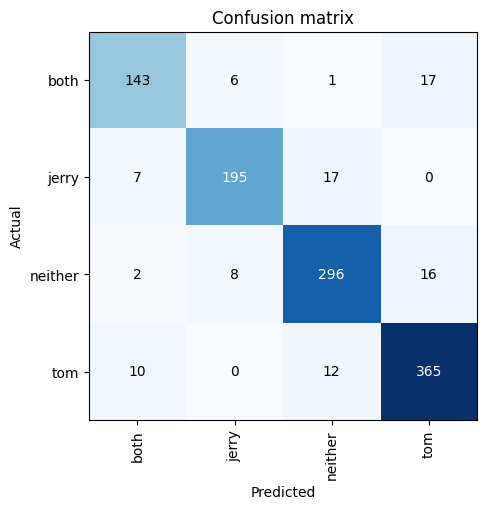

In [ ]:
interpretation.plot_confusion_matrix(figsize=(5, 5))

Rows are the actual classes and columns are the predictions. Of the 1,095 validation images:

| Class | Correct | Accuracy |
|---|---|---|
| `tom` | 365 of 387 | 94% |
| `neither` | 296 of 322 | 92% |
| `jerry` | 195 of 219 | 89% |
| `both` | 143 of 167 | 86% |

That is 1,095 − 999 = 96 errors, an error rate of 8.8%, matching the final error rate from training. The model is best at the largest class, `tom`, and worst at the smallest and hardest class, `both`.

The model never confuses Tom with Jerry (0 errors in either direction): it has clearly learned to tell the two characters apart. Almost all mistakes are about whether a character is **present** at all. To list the most common mistakes, we use the `most_confused` method, showing pairs that occur at least 10 times.

In [ ]:
interpretation.most_confused(min_val=10)

Each entry gives the actual class, the predicted class and the number of times the mistake occurred. The five most common mistakes are:

- `both` predicted as `tom` (17): Jerry is in the frame but missed, probably because he is small or hidden.
- `jerry` predicted as `neither` (17): Jerry is missed entirely, for the same reason.
- `neither` predicted as `tom` (16): the model sees Tom where there is none, possibly another grey character or object.
- `tom` predicted as `neither` (12): Tom is missed, probably when only part of him is visible.
- `tom` predicted as `both` (10): the model sees a Jerry that is not there.

The most common failure is therefore missing a small or partly visible character, especially Jerry.

### Images with the highest loss

The loss is large when the model is confident and wrong, so the images with the highest loss are the best place to look for the model's weaknesses. Each title shows the prediction, the actual class, the loss, and the probability the model assigned to its prediction.

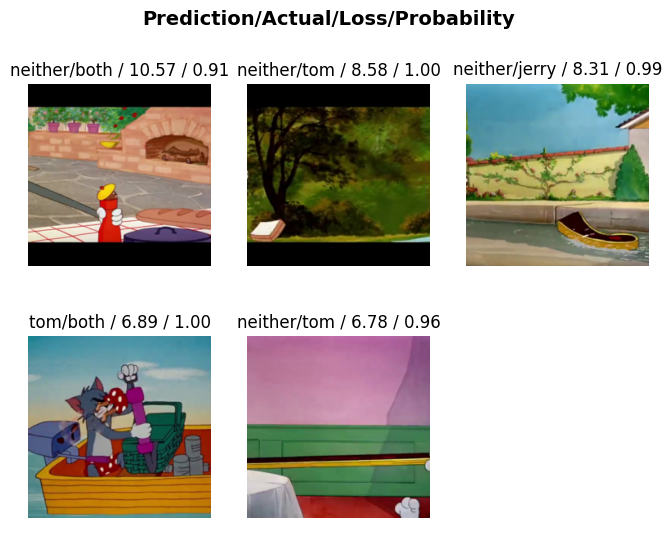

In [ ]:
interpretation.plot_top_losses(5, figsize=(8, 6))

All five images are mistakes, and the model was very confident about each of them (probabilities of 0.91 to 1.00). Four of the five were predicted as `neither`:

- **Probable labelling errors.** In the second image (labelled `tom`), a dark forest scene with a book on the ground, and the third image (labelled `jerry`), a small boat on water, the named character is not visible at all. Here the model's answer, `neither`, looks correct and the dataset's label looks wrong.
- **Partial views.** The fifth image (labelled `tom`) shows only a white glove at the bottom edge of the frame. It is understandable that the model answered `neither`.
- **Hidden characters.** The fourth image (labelled `both`) shows Tom in a boat with a picnic basket. Jerry may be hidden in or behind the basket, but he is not clearly visible, so the prediction `tom` is reasonable. The first image (labelled `both`) shows an outdoor kitchen scene with a small red-and-yellow figure and part of a grey arm, which is hard to interpret even for a person.

These images show that some of the measured error comes from **incorrect or ambiguous labels** in the dataset rather than from the model, so the true error rate may be somewhat lower than 8.8%. They also confirm that the model struggles when a character is small, hidden or only partly in the frame.

# Deployment

A trained model is useful when it is applied to new data. The `predict` method of the learner takes a single image and returns the predicted class, its index, and the probability of each class.

### A frame from the dataset

We first predict the class of an example frame from the dataset. The classes are stored in alphabetical order in `dls.vocab` (`both`, `jerry`, `neither`, `tom`), so we print the probability of every class instead of picking one by its index. We also print the frame's actual label to check the prediction.

In [ ]:
example_image = PILImage.create(file_names[500])

predicted_label, _, class_probabilities = learn.predict(example_image)

print(f"Actual class:    {label_function(file_names[500])}")
print(f"Predicted class: {predicted_label}")
for class_name, probability in zip(dls.vocab, class_probabilities):
    print(f"Probability it is {class_name:<8} = {probability.item():.6f}")
example_image.to_thumb(192)

The model predicts `both` with a probability of 0.98, and gives each of the other classes less than 0.02. The frame shows two characters from behind standing at a wall: a large grey one and a smaller dark one. The printed actual class shows whether the prediction is correct.

Keep in mind that this frame comes from the dataset itself, possibly from the training set, so it is an easy test.

### A picture from outside the dataset

A harder test is a picture that is not a frame from the cartoon. To show a picture next to the model's prediction, we define a function that runs `learn.predict` on an image and draws the image beside a bar chart of the predicted probability for each class.

In [ ]:
def plot_prediction(image):
    predicted_label, _, class_probabilities = learn.predict(image)

    figure, (image_axis, probability_axis) = plt.subplots(1, 2, figsize=(8, 4))

    image_axis.imshow(image)
    image_axis.axis('off')
    image_axis.set_title(f"Prediction: {predicted_label}")

    sns.barplot(x=class_probabilities, y=list(dls.vocab), orient='h', ax=probability_axis)
    probability_axis.set_xlabel("Probability")
    probability_axis.set_ylabel("Class Label")
    probability_axis.set_title("Prediction Probabilities")

    plt.tight_layout()
    plt.show()

Defining the function produces no output; we use it below.

Download the picture of Jerry from Wikipedia. Some websites block requests that do not come from a browser, so we send a browser-like `User-Agent` header, and we check that the response really is an image before saving it.

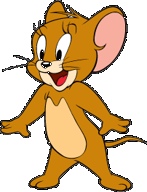

In [ ]:
jerry_image_url = "https://upload.wikimedia.org/wikipedia/en/2/2f/Jerry_Mouse.png"

response = requests.get(jerry_image_url, headers={"User-Agent": "Mozilla/5.0"})
response.raise_for_status()
assert response.headers.get("Content-Type", "").startswith("image"), f"Not an image: {response.headers.get('Content-Type')}"

with open("jerry.png", "wb") as image_file:
    image_file.write(response.content)

jerry_image = PILImage.create("jerry.png")
jerry_image.to_thumb(192)

The download worked. The picture is the official character artwork of Jerry: he stands facing the viewer, smiling, with his whole body visible against a black background. It looks quite different from the cartoon frames: it is taller than it is wide, has no scenery, and Jerry fills the whole picture instead of being a small figure in a scene.

Predict the class of the picture and plot the prediction.

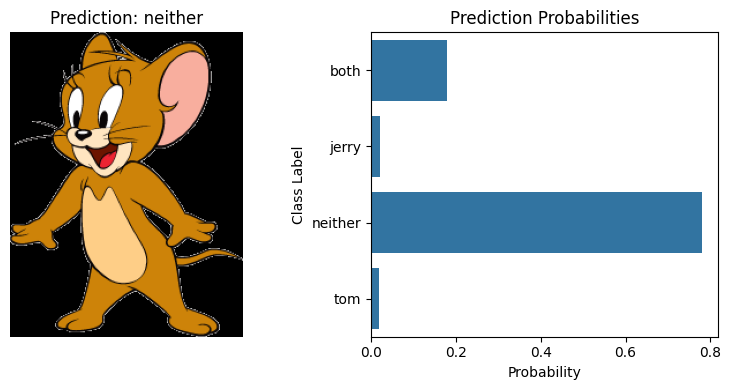

In [ ]:
plot_prediction(jerry_image)

The model gets this picture **wrong**. It predicts `neither` with a probability of about 0.78, gives `both` about 0.18, and gives the correct class, `jerry`, only about 0.02.

This is the most revealing result in the notebook. On frames from the cartoon the model is right about 91% of the time, yet it fails on the clearest possible picture of Jerry. The likely reason is that the picture is very different from the training data: the model has learned what Jerry looks like *as a small figure inside a cartoon scene*, and a large, clean drawing on a black background, with no scenery, does not match what it has seen. Machine learning models often fail in this way when the new data differ from the training data, a problem known as **distribution shift**.

# Conclusion

Starting from ResNet-34 pretrained on photographs, fine-tuning for four epochs produced a model that classifies *Tom and Jerry* frames into four classes (`tom`, `jerry`, `both`, `neither`) with a **validation error rate of 8.8% (96 of 1,095 frames)**. Transfer learning worked well even though ImageNet contains no cartoons: training the whole network cut the error rate from 26.6% to 8.8%.

What the model does well and where it fails:

- It never confuses Tom with Jerry. Almost all errors are about whether a character is present, most often missing a small or partly visible Jerry (`both` predicted as `tom`, `jerry` predicted as `neither`).
- Several of the highest-loss frames appear to be **labelling errors** in the dataset, so part of the measured error is not the model's fault.
- It does **not** generalise to images that look different from the training frames: it misclassified an official picture of Jerry as `neither`.

Limitations:

- The validation frames come from the same episodes as the training frames, and neighbouring video frames are near-copies, so the 8.8% error rate is probably optimistic for new episodes.
- The classes are unbalanced, with the fewest examples of `both`, the class the model finds hardest.

Possible next steps are to split the data by episode or by blocks of consecutive frames for a more honest validation, to correct the mislabelled frames, to use data augmentation (random crops, zooms and lighting changes) to help with small and partial characters, and to add other kinds of Tom and Jerry images to the training data so the model works beyond cartoon frames.